# Trading project — Proximal Policy Optimization (PPO)

A separate adaptation of `Project_Instruction.ipynb`. The original DQN notebook and course PDF remain unchanged. This version implements PPO in PyTorch, establishes a PPO baseline, tunes it using chronological validation, and compares the selected policy with DQN and market benchmarks.

**Run All** validates the expanded data, runs a short PPO training smoke test, and displays the completed tuning results when available. It reloads the selected checkpoint and independently verifies its evaluation return. Set `RETRAIN_ALL=True` in the experiment cell to train and evaluate the full search. Historical results in `eval/ppo/` belong to the previous data/action setup and are not results for this version. Select the **RL Python 3.12** kernel and run from the project folder. New PPO outputs live in `eval/ppo_202004_nine_actions/`.

## Overview
In this project, you will implement a deep reinforcement learning (DRL) algorithm covered in this course and train an agent in a trading environment. You will then use the observed results to guide and assess improvements to your initial implementation.

### Project Requirements

1. **Implement a course algorithm.** Choose one DRL algorithm covered in the course, implement it, and train an initial agent to establish a baseline. Explain why this algorithm is suitable for the task.
2. **Analyse the initial results.** Examine training behaviour and agent performance to identify limitations and opportunities for improvement.
3. **Optimise based on evidence.** Use your observations to motivate changes, for example to hyperparameters, network architecture, input features, reward design, or the training procedure. Compare the results with your baseline and explain what worked, what did not, and why.

### Deliverables and Schedule

- **Upload your code:** Jupyter Notebooks or Python scripts containing the algorithm implementation, training, optimisation experiments, and evaluation.
- **Upload `evaluation_results.csv`:** Generate this file for your final agent using the provided evaluation function.
- **Give a 10–15-minute presentation, followed by Q&A:** Explain your choice of algorithm, the initial results, your optimisation ideas and their rationale, the experiments conducted, and the resulting performance compared with the baseline.

No written report is required. Upload the code and evaluation CSV **before your presentation**. Presentations will take place during **the last class session**.

### Environment
We will use Gym Trading Env as our trading environment. (https://gym-trading-env.readthedocs.io/en/latest/)

- This is a gymnasium-compatible environment designed to simulate trading (stocks or crypto) from historical market data.
- Its goal is to provide a fast and customizable platform for training RL agents in a trading scenario.

We will use BTC/USDT hour step historical data from Binance for training and evaluation. All students must use the same fixed evaluation period: **2026-08-17 00:00 UTC to 2026-09-17 00:00 UTC (exclusive)**, covering all complete days from August 17 through September 16. Do not change the evaluation dates for submission. This PPO extension uses training history from April 1, 2020, with no evaluation overlap, as requested. This extends the original assignment’s one-year training rule.

Following code blocks demonstrate how to set up the environment and evaluate your agent.

### Grading Criteria

- **Implementation — 25%:** Correct implementation of a DRL algorithm covered in the course, with a functioning training and evaluation process.
- **Optimisation — 50%:** Analysis of observed results, well-motivated improvements, systematic experiments, and clear comparisons with the initial baseline. Explain both successful and unsuccessful changes.
- **Presentation — 25%:** Clear explanation of the algorithm choice, optimisation rationale, experimental results, and conclusions.

**Bonus:** The top-performing agent receives a **15% bonus**, based on the submitted evaluation results.


## 1. Environment and cached market data

The same dependencies as the DQN project are sufficient; no additional RL library is needed. Install `requirements.txt` once into Python 3.12. The code below contains the PPO implementation; `ppo_trading.py` exposes the identical implementation for repeatable multi-process experiments.

The expanded Binance spot BTC/USDT cache starts on March 25, 2020, providing seven days of feature warm-up before training starts on April 1, 2020. The evaluation window remains August 17–September 17, 2026 (end exclusive). Rebuild the cache with `.venv-rl/bin/python btc_data.py`; Run All uses the local cache without network access. Download provenance and checksums are stored beside it. The source omits 24 hourly candles. They remain absent: rolling features restart after each gap (with a fresh warm-up), and training samples only continuous hourly windows. No synthetic candles are inserted. See [Binance public-data documentation](https://github.com/binance/binance-public-data).

In [1]:
# %pip install -r requirements.txt
from pathlib import Path
from dataclasses import dataclass, asdict
import hashlib
import json
import inspect
import subprocess
import sys
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Categorical
import gymnasium as gym
import gym_trading_env
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import ppo_trading as experiment
from trading_tuning import ROOT, FOLDS, SEEDS, rollout
from btc_data import DATA_PATH, TRAIN_START, EVAL_START, EVAL_END, load_data
from ppo_trading import CONFIRM_STEPS, AGGREGATIONS, POSITIONS, config_from_dict
from trading_tuning import add_features as shared_add_features

torch.set_num_threads(1)
OUT = experiment.OUT
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
print('PPO artifacts:', OUT)

Python: 3.12.14 | PyTorch: 2.2.2
PPO artifacts: /Users/alivakof/Desktop/RL/eval/ppo_202004_nine_actions


### Causal features and strict date boundaries

The basic state contains the one-hour return, OHLC ratios, and relative volume. The momentum state adds returns over 1/6/24/72/168 hours, volatility, moving-average deviations, candle range/body, and relative volume. Two environment features describe the previous and current real position. Each training fold fits its own scaler; validation and evaluation never update it.

OHLCV candles are indexed by opening time. Their features become available at candle close; the simulator chooses exposure at that close for the next close-to-close return. This is an idealized execution assumption: trading fees and borrowing costs are included; spread, slippage, and latency are absent.

In [2]:
def add_features(raw, kind='momentum'):
    """Restart rolling features at missing hours; never impute market candles."""
    segments = raw.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
    return pd.concat([shared_add_features(part, kind) for _, part in raw.groupby(segments)])

In [3]:
raw = load_data()
pre_evaluation = raw.loc[raw.index < EVAL_START]
features = add_features(pre_evaluation, 'momentum')
df_train = features.loc[features.index >= TRAIN_START].copy()
expected_training = pd.date_range(TRAIN_START, EVAL_START, freq='h', inclusive='left')
assert df_train.index.min() == TRAIN_START and df_train.index.max() == expected_training[-1]
assert df_train.index.is_unique and df_train.index.is_monotonic_increasing
print('Missing source hours:', len(raw.attrs.get('missing_hours', [])))
print('Additional warm-up rows excluded after gaps:', len(expected_training.difference(df_train.index)) - len(raw.attrs.get('missing_hours', [])))
print(f'{len(raw):,} cached candles; {len(df_train):,} training candles')
print('Training:', df_train.index.min(), 'through', df_train.index.max())
folds = pd.DataFrame([
    {'fold': i, 'training_start': TRAIN_START, 'training_end_exclusive': a,
     'validation_start': a, 'validation_end_exclusive': b,
     'training_hours': int(((df_train.index >= TRAIN_START) & (df_train.index < a)).sum()),
     'validation_hours': int(((df_train.index >= a) & (df_train.index < b)).sum())}
    for i, (a, b) in enumerate(FOLDS)
])
display(folds)
display(df_train.head(3))

Missing source hours: 24
Additional warm-up rows excluded after gaps: 1881
56,784 cached candles; 53,991 training candles
Training: 2020-04-01 00:00:00+00:00 through 2026-08-16 23:00:00+00:00


,fold,training_start,training_end_exclusive,validation_start,validation_end_exclusive,training_hours,validation_hours
0,0,2020-04-01 00:00:00+00:00,2026-01-19 00:00:00+00:00,2026-01-19 00:00:00+00:00,2026-02-18 00:00:00+00:00,48951,720
1,1,2020-04-01 00:00:00+00:00,2026-03-20 00:00:00+00:00,2026-03-20 00:00:00+00:00,2026-04-19 00:00:00+00:00,50391,720
2,2,2020-04-01 00:00:00+00:00,2026-05-19 00:00:00+00:00,2026-05-19 00:00:00+00:00,2026-06-18 00:00:00+00:00,51831,720
3,3,2020-04-01 00:00:00+00:00,2026-07-18 00:00:00+00:00,2026-07-18 00:00:00+00:00,2026-08-17 00:00:00+00:00,53271,720


,open,high,low,close,volume,feature_return_1,feature_return_6,feature_return_24,feature_return_72,feature_return_168,feature_volatility_24,feature_volatility_168,feature_trend_24,feature_trend_72,feature_trend_168,feature_range,feature_body,feature_volume
date_open,,,,,,,,,,,,,,,,,,
2020-04-01 00:00:00+00:00,6412.14,6426.52,6239.34,6305.12,9061.280945,-0.016566,-0.024634,-0.021097,0.014737,-0.060743,0.006609,0.008893,-0.016983,-0.008101,-0.016382,0.029687,-0.016690,0.852462
2020-04-01 01:00:00+00:00,6305.50,6327.93,6285.25,6293.64,2275.174783,-0.001822,-0.026627,-0.034425,0.012279,-0.048371,0.006060,0.008828,-0.017297,-0.009638,-0.017962,0.006781,-0.001881,-0.527644
2020-04-01 02:00:00+00:00,6291.99,6320.49,6287.60,6317.40,1805.203416,0.003768,-0.023482,-0.020720,0.018860,-0.042940,0.005866,0.008833,-0.012514,-0.005738,-0.014088,0.005206,0.004038,-0.754920


### Trading environment

Every PPO candidate uses `[-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1]`. These are nine discrete target exposures: negative values short BTC, zero holds cash, and positive values hold BTC. The environment takes integer action indices 0–8; cash is index 4. The actor outputs nine categorical probabilities. This is a discrete spectrum, not a continuous action space. Every policy starts in cash with portfolio value 1,000. The fee parameter is 0.0001 and hourly borrowing-interest parameter is 0.000003. Evaluation covers the complete assigned history; training uses randomly located episodes of at most 720 candles.

In [4]:
def make_env(frame, positions, duration='max'):
    frame = frame.copy()
    frame.index = frame.index.tz_convert('UTC').tz_localize(None)
    return gym.make('TradingEnv', name='BTCUSDT', df=frame, positions=list(positions),
                    initial_position=0, trading_fees=.0001, borrow_interest_rate=.000003,
                    max_episode_duration=duration, verbose=0)

In [5]:
example_env = make_env(df_train.iloc[:400], POSITIONS)
np.random.seed(23)
observation, info = example_env.reset(seed=23)
print('Observation shape:', observation.shape, '| Actions:', example_env.action_space)
next_observation, reward, terminated, truncated, info = example_env.step(POSITIONS.index(0.))  # Cash is index 4
print('Cash transition log reward:', reward)
example_env.close()

Observation shape: (15,) | Actions: Discrete(9)
Cash transition log reward: 0.0


## 2. PPO implementation

PPO learns a **categorical actor** $\pi_\theta(a|s)$ and a **critic** $V_\phi(s)$. Stochastic action sampling provides training exploration; evaluation takes the most probable action. PPO suits this continuous-observation, discrete-position problem.

Fresh on-policy rollouts supply old action log probabilities and advantages. Several minibatch passes optimize the clipped objective

$$L^{\rm clip}=\mathbb{E}[\min(r_t\hat A_t,\;\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t)],\qquad
r_t=\frac{\pi_\theta(a_t|s_t)}{\pi_{\rm old}(a_t|s_t)}.$$

The minimized loss is $-L^{\rm clip}+c_v\tfrac12(V-R)^2-c_e H(\pi)$. Advantages are normalized, gradients are clipped, and an approximate-KL threshold can stop an update early. Separate two-layer actor/critic networks use tanh activations and orthogonal initialization. Completed rollouts are discarded after updating.

Reference: [Schulman et al., *Proximal Policy Optimization Algorithms* (2017)](https://arxiv.org/abs/1707.06347).

In [6]:
@dataclass(frozen=True)
class PPOConfig:
    name: str
    features: str = 'momentum'
    positions: tuple = POSITIONS
    hidden: int = 64
    lr: float = 3e-4
    gamma: float = .99
    gae_lambda: float = .95
    clip_range: float = .2
    entropy_coef: float = .01
    value_coef: float = .5
    max_grad_norm: float = .5
    target_kl: float = .02
    epochs: int = 6
    batch_size: int = 256
    n_envs: int = 4
    rollout_steps: int = 256
    reward_scale: float = 100.
    turnover_penalty: float = 0.
    anneal_lr: bool = True


class ActorCritic(nn.Module):
    def __init__(self, dimensions, actions, hidden):
        super().__init__()
        # Separate networks prevent value regression from dominating actor features.
        def mlp(outputs, output_gain):
            net = nn.Sequential(nn.Linear(dimensions, hidden), nn.Tanh(),
                                nn.Linear(hidden, hidden), nn.Tanh(),
                                nn.Linear(hidden, outputs))
            for layer in net:
                if isinstance(layer, nn.Linear):
                    nn.init.orthogonal_(layer.weight, np.sqrt(2))
                    nn.init.zeros_(layer.bias)
            nn.init.orthogonal_(net[-1].weight, output_gain)
            return net
        self.actor = mlp(actions, .01)
        self.critic = mlp(1, 1.)

    def forward(self, states):
        return Categorical(logits=self.actor(states)), self.critic(states).squeeze(-1)

### Generalized advantage estimation and episode boundaries

$$\delta_t=r_t+\gamma(1-\text{terminated}_t)V(s_{t+1})-V(s_t),\qquad
\hat A_t=\delta_t+\gamma\lambda(1-\text{done}_t)\hat A_{t+1}.$$

A time limit bootstraps from the **final observation before reset** but stops the advantage recursion across episodes. Bankruptcy is a true terminal and has zero bootstrap. This distinction also applies when a training rollout ends partway through an episode.

In [7]:
def compute_gae(rewards, values, next_values, terminated, done, gamma, gae_lambda):
    """Time-major [T, N] GAE; bootstrap truncations but never cross resets.

    `next_values` must refer to the transition's final observation, not the
    reset observation. A bankruptcy/true terminal has no future value.
    """
    arrays = [np.asarray(a, np.float32) for a in
              (rewards, values, next_values, terminated, done)]
    rewards, values, next_values, terminated, done = arrays
    if rewards.ndim != 2 or any(a.shape != rewards.shape for a in arrays):
        raise ValueError('GAE inputs must have matching [time, environment] shapes')
    advantages = np.zeros_like(rewards)
    carry = np.zeros(rewards.shape[1], np.float32)
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * (1-terminated[t]) * next_values[t] - values[t]
        carry = delta + gamma * gae_lambda * (1-done[t]) * carry
        advantages[t] = carry
    return advantages, advantages + values


def clipped_policy_loss(log_probs, old_log_probs, advantages, clip_range):
    ratio = (log_probs-old_log_probs).exp()
    unclipped = ratio * advantages
    clipped = ratio.clamp(1-clip_range, 1+clip_range) * advantages
    return -torch.minimum(unclipped, clipped).mean()

In [8]:
class PPOAgent:
    def __init__(self, config, columns, mean, std, seed=23):
        self.config, self.columns, self.seed = config, list(columns), seed
        self.positions = tuple(config.positions)
        self.mean = np.asarray(mean, np.float32)
        self.std = np.asarray(std, np.float32)
        if len(self.mean) != len(self.columns)+2 or np.any(self.std <= 0):
            raise ValueError('Scaler must match static features plus two position features')
        torch.manual_seed(seed)
        self.rng = np.random.default_rng(seed)
        self.network = ActorCritic(len(self.mean), len(self.positions), config.hidden)
        self.optimizer = torch.optim.Adam(self.network.parameters(), lr=config.lr, eps=1e-5)
        self.updates = 0

    def encode(self, states):
        encoded = np.clip((np.asarray(states, np.float32)-self.mean)/self.std, -8, 8)
        if not np.isfinite(encoded).all():
            raise FloatingPointError('Non-finite observation')
        return encoded

    def probabilities(self, state):
        with torch.no_grad():
            distribution, _ = self.network(torch.from_numpy(self.encode(state)))
        return distribution.probs.numpy()

    def choose_action_eval(self, state):
        return int(self.probabilities(state).argmax())

    def update(self, states, actions, old_log_probs, advantages, returns, progress):
        cfg = self.config
        states = torch.as_tensor(states.reshape(-1, len(self.mean)))
        actions = torch.as_tensor(actions.reshape(-1), dtype=torch.long)
        old_log_probs = torch.as_tensor(old_log_probs.reshape(-1))
        advantages = torch.as_tensor(advantages.reshape(-1))
        advantages = (advantages-advantages.mean()) / (advantages.std(unbiased=False)+1e-8)
        returns = torch.as_tensor(returns.reshape(-1))
        lr = cfg.lr * (max(.1, 1-progress) if cfg.anneal_lr else 1.)
        for group in self.optimizer.param_groups:
            group['lr'] = lr
        metrics, stopped = [], False
        for _ in range(cfg.epochs):
            permutation = self.rng.permutation(len(actions))
            for offset in range(0, len(actions), cfg.batch_size):
                indices = permutation[offset:offset+cfg.batch_size]
                distribution, values = self.network(states[indices])
                log_probs = distribution.log_prob(actions[indices])
                log_ratio = log_probs-old_log_probs[indices]
                with torch.no_grad():
                    approx_kl = ((log_ratio.exp()-1)-log_ratio).mean()
                if cfg.target_kl and approx_kl > 1.5*cfg.target_kl:
                    stopped = True
                    break
                actor_loss = clipped_policy_loss(log_probs, old_log_probs[indices],
                                                 advantages[indices], cfg.clip_range)
                value_loss = .5 * (values-returns[indices]).square().mean()
                entropy = distribution.entropy().mean()
                loss = actor_loss + cfg.value_coef*value_loss - cfg.entropy_coef*entropy
                if not torch.isfinite(loss):
                    raise FloatingPointError('Non-finite PPO loss')
                self.optimizer.zero_grad(set_to_none=True)
                loss.backward()
                grad_norm = nn.utils.clip_grad_norm_(self.network.parameters(), cfg.max_grad_norm)
                if not torch.isfinite(grad_norm):
                    raise FloatingPointError('Non-finite PPO gradient')
                self.optimizer.step()
                self.updates += 1
                metrics.append([actor_loss.item(), value_loss.item(), entropy.item(),
                                approx_kl.item(), ((log_ratio.exp()-1).abs()>cfg.clip_range).float().mean().item()])
            if stopped:
                break
        if not metrics:
            raise RuntimeError('No PPO update completed')
        result = dict(zip(['actor_loss', 'value_loss', 'entropy', 'approx_kl', 'clip_fraction'],
                          np.mean(metrics, axis=0).tolist()))
        with torch.no_grad():
            predicted = self.network.critic(states).squeeze(-1)
            variance = returns.var(unbiased=False)
            result['explained_variance'] = float(1-(returns-predicted).var(unbiased=False)/(variance+1e-8))
        return {**result, 'learning_rate': lr, 'kl_early_stop': int(stopped), 'updates': self.updates}

    def payload(self):
        return dict(config=asdict(self.config), columns=self.columns, mean=self.mean.tolist(),
                    std=self.std.tolist(), seed=self.seed, weights=self.network.state_dict(),
                    updates=self.updates)

    @classmethod
    def from_payload(cls, payload):
        agent = cls(config_from_dict(payload['config']), payload['columns'],
                    payload['mean'], payload['std'], payload['seed'])
        agent.network.load_state_dict(payload['weights'])
        agent.network.eval()
        agent.updates = payload['updates']
        return agent

### Training loop

Four environments sample independent, continuous hourly windows. Episodes never cross missing source candles or feature warm-up gaps. Feature normalization uses the supplied training frame only. Learning rewards are log portfolio returns multiplied by 100, with an optional penalty proportional to absolute position change. A bankruptcy penalty corrects the environment's zero terminal reward. **Reported returns use the actual unshaped portfolio value**, including the environment's costs.

This environment release uses NumPy's global generator for random starts, so every reset explicitly seeds it. PyTorch and minibatch sampling also receive the run's seed.

In [9]:
class TrainingWindowEnv(gym.Wrapper):
    """Sample complete hourly windows; neither features nor episodes cross gaps."""
    def __init__(self, frame, positions, duration):
        self.frame, self.positions, self.duration = frame, positions, duration
        times = frame.index.asi8
        # Ordered unique timestamps mean equal endpoint spacing implies no interior gaps.
        if not frame.index.is_monotonic_increasing or not frame.index.is_unique:
            raise ValueError('Training timestamps must be ordered and unique')
        self.starts = np.flatnonzero(times[duration-1:] - times[:len(times)-duration+1]
                                     == (duration-1)*pd.Timedelta(hours=1).value)
        if not len(self.starts):
            raise ValueError('No continuous hourly training window of the requested duration')
        super().__init__(make_env(frame.iloc[:duration], positions))

    def reset(self, *, seed=None, options=None):
        start = int(np.random.choice(self.starts))
        self.env.close()
        self.env = make_env(self.frame.iloc[start:start+self.duration], self.positions)
        return self.env.reset(seed=seed, options=options)


def fit(frame, cfg, seed, steps=CONFIRM_STEPS):
    """Synchronous independent episodes; each rollout is discarded after updating."""
    if steps < cfg.n_envs or steps % cfg.n_envs:
        raise ValueError('Training steps must be a positive multiple of n_envs')
    if len(frame) < 3:
        raise ValueError('Training requires at least three candles')
    torch.set_num_threads(1)
    columns = [c for c in frame if c.startswith('feature_')]
    mean = np.r_[frame[columns].mean().to_numpy(), [0., 0.]]
    std = np.r_[frame[columns].std().clip(lower=1e-6).to_numpy(), [1., 1.]]
    agent = PPOAgent(cfg, columns, mean, std, seed)
    environments = [TrainingWindowEnv(frame, cfg.positions, duration=min(720, len(frame)-1))
                    for _ in range(cfg.n_envs)]
    episodes = np.zeros(cfg.n_envs, dtype=int)

    def reset(index):
        reset_seed = seed + index + int(episodes[index])*cfg.n_envs
        # This TradingEnv release uses global NumPy RNG for random starts.
        np.random.seed(reset_seed)
        state, _ = environments[index].reset(seed=reset_seed)
        episodes[index] += 1
        return state

    logs, total = [], 0
    try:
        raw_states = np.stack([reset(i) for i in range(cfg.n_envs)])
        while total < steps:
            length = min(cfg.rollout_steps, (steps-total)//cfg.n_envs)
            shape = (length, cfg.n_envs)
            states = np.empty((*shape, len(mean)), np.float32)
            next_states = np.empty_like(states)
            actions = np.empty(shape, np.int64)
            rewards, values, log_probs, terminated, done = [np.empty(shape, np.float32) for _ in range(5)]
            raw_rewards = []
            for t in range(length):
                states[t] = agent.encode(raw_states)
                with torch.no_grad():
                    distribution, value = agent.network(torch.from_numpy(states[t]))
                    action = distribution.sample()
                    actions[t] = action.numpy()
                    values[t] = value.numpy()
                    log_probs[t] = distribution.log_prob(action).numpy()
                for i, env in enumerate(environments):
                    future, reward, terminal, truncated, _ = env.step(int(actions[t, i]))
                    # Bankruptcy returns zero in TradingEnv; give learning a real penalty.
                    shaped_reward = -1. if terminal else float(reward)
                    shaped_reward -= cfg.turnover_penalty * abs(cfg.positions[actions[t,i]]-float(raw_states[i,-2]))
                    rewards[t,i] = shaped_reward * cfg.reward_scale
                    terminated[t,i], done[t,i] = terminal, terminal or truncated
                    # Capture final observation before resetting for GAE bootstrapping.
                    next_states[t,i] = np.zeros(len(mean), np.float32) if terminal else agent.encode(future)
                    raw_rewards.append(float(reward))
                    raw_states[i] = reset(i) if terminal or truncated else future
            with torch.no_grad():
                next_values = agent.network.critic(torch.from_numpy(next_states.reshape(-1,len(mean))))
                next_values = next_values.numpy().reshape(shape)
            if not np.isfinite(rewards).all():
                raise FloatingPointError('Non-finite PPO reward')
            advantages, returns = compute_gae(rewards, values, next_values, terminated, done,
                                             cfg.gamma, cfg.gae_lambda)
            total += length*cfg.n_envs
            diagnostics = agent.update(states, actions, log_probs, advantages, returns, total/steps)
            logs.append(dict(steps=total, episodes=int(episodes.sum()-cfg.n_envs),
                             mean_raw_step_reward=float(np.mean(raw_rewards)), **diagnostics))
    finally:
        for env in environments:
            env.close()
    agent.network.eval()
    return agent, pd.DataFrame(logs)

### Ensemble and checkpoint persistence

The search compares two predefined deterministic rules: choose the maximum mean action probability, or trade only when all three seeded policies agree (otherwise cash). The checkpoint stores the actor and critic, feature order, training scaler, configuration, seeds, and aggregation rule.

In [10]:
class PPOEnsemble:
    def __init__(self, agents, aggregation='mean_probability'):
        if not agents or aggregation not in AGGREGATIONS:
            raise ValueError('Unknown aggregation or empty ensemble')
        self.agents, self.aggregation = agents, aggregation
        self.config, self.positions = agents[0].config, agents[0].positions
        self.columns = agents[0].columns
        if any(a.config != self.config or a.columns != self.columns for a in agents):
            raise ValueError('Ensemble configurations and feature orders must match')

    def choose_action_eval(self, state):
        probabilities = np.array([a.probabilities(state) for a in self.agents])
        if self.aggregation == 'mean_probability':
            return int(probabilities.mean(axis=0).argmax())
        votes = probabilities.argmax(axis=1)
        return int(votes[0]) if np.all(votes == votes[0]) else self.positions.index(0.)

    def save(self, path):
        torch.save(dict(format='trading_ppo_v1', aggregation=self.aggregation,
                        agents=[a.payload() for a in self.agents]), path)

    @classmethod
    def load(cls, path):
        payload = torch.load(path, map_location='cpu', weights_only=True)
        if payload.get('format') != 'trading_ppo_v1':
            raise ValueError('Not a PPO trading checkpoint')
        return cls([PPOAgent.from_payload(p) for p in payload['agents']], payload['aggregation'])

### Expanded-history smoke test

A 2,048-transition fit verifies the nine-action actor, training loop, and checkpoint reload. This is an integration check, not a performance experiment.

In [11]:
smoke_config = PPOConfig('nine_action_smoke')
smoke_agent, smoke_history = fit(df_train, smoke_config, seed=23, steps=2048)
assert smoke_agent.positions == POSITIONS
assert smoke_agent.network.actor[-1].out_features == 9
assert np.isfinite(smoke_history.to_numpy()).all()
OUT.mkdir(parents=True, exist_ok=True)
smoke_path = OUT / 'smoke_ppo_agent.pth'
PPOEnsemble([smoke_agent]).save(smoke_path)
smoke_loaded = PPOEnsemble.load(smoke_path)
assert smoke_loaded.positions == POSITIONS
print('Nine-action real-data training and checkpoint reload passed.')
display(smoke_history.tail())

Nine-action real-data training and checkpoint reload passed.


,steps,episodes,mean_raw_step_reward,actor_loss,value_loss,entropy,approx_kl,clip_fraction,explained_variance,learning_rate,kl_early_stop,updates
0,1024,0,-0.000071,-0.002071,0.530518,2.197150,5.785690e-05,0.0,0.007023,0.00015,0,24
1,2048,0,-0.000092,-0.000162,0.749026,2.197007,7.468334e-07,0.0,-0.092341,0.00003,0,48


## 3. Baseline and registered tuning experiment

The baseline uses basic features, learning rate 0.0003, discount 0.99, no entropy bonus, and a fixed learning rate. All candidates use the same causal data, reward scaling, costs, architecture, rollout size, and evaluation rules. Candidate changes are hypotheses to check, not assumed improvements.

1. Screen seven configurations on four earlier 30-day folds, using seed 23 and 16,384 transitions per fit.
2. Confirm the strongest two configurations plus the baseline using seeds 23, 42, and 71 and 49,152 transitions per fit.
3. Select the configuration and ensemble rule by `mean(log return) − 0.25 × mean(drawdown magnitude) − 0.10 × std(log return)` across the four folds.
4. Freeze the choice, refit on the complete history from April 1, 2020, and compare on the assignment month.

The assignment month was viewed during earlier DQN work. It is explicitly a **reused holdout**, and does not choose these PPO settings. The source/data fingerprints in `protocol.json` prevent mixing a changed implementation with cached trial results. Workers are ordinary independent Python training processes.

In [12]:
candidates = pd.DataFrame([asdict(c) for c in experiment.CONFIGS])
display(candidates[['name', 'features', 'positions', 'lr', 'gamma', 'gae_lambda',
                    'clip_range', 'entropy_coef', 'turnover_penalty', 'anneal_lr']])

RETRAIN_ALL = False
if RETRAIN_ALL:
    subprocess.run([sys.executable, str(ROOT / 'ppo_trading.py'), 'all', '--workers', '3'],
                   cwd=ROOT, check=True)
protocol = experiment.protocol()
assert not protocol['evaluation_used_for_selection']
if (OUT / 'screening_summary.csv').exists():
    display(pd.read_csv(OUT / 'screening_summary.csv').set_index('config').round(4))
else:
    print('Full experiment has not run for this data/action setup. Set RETRAIN_ALL=True to run it.')

,name,features,positions,lr,gamma,gae_lambda,clip_range,entropy_coef,turnover_penalty,anneal_lr
0,ppo_baseline,basic,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.000,0.0000,False
1,ppo_momentum,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.010,0.0000,True
2,ppo_cautious,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0001,0.99,0.95,0.1,0.005,0.0000,True
3,ppo_short_horizon,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.95,0.90,0.2,0.010,0.0000,True
4,ppo_turnover,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.95,0.95,0.2,0.010,0.0003,True
5,ppo_low_turnover,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.010,0.0001,True
6,ppo_exploration,momentum,"(-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7...",0.0003,0.99,0.95,0.2,0.030,0.0001,True


,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_momentum,0.0121,0.0644,0.0137,-0.0729,-0.0595,188.00,-0.0092
ppo_low_turnover,0.0079,0.0642,0.0095,-0.0749,-0.0609,172.25,-0.0138
ppo_turnover,0.0063,0.0513,0.0073,-0.0460,-0.0617,149.50,-0.0142
ppo_cautious,-0.0061,0.0436,-0.0054,-0.0649,-0.0667,190.50,-0.0271
ppo_exploration,-0.0166,0.0574,-0.0152,-0.0658,-0.0685,184.25,-0.0394
ppo_short_horizon,-0.0451,0.0433,-0.0434,-0.0820,-0.0660,257.50,-0.0659
ppo_baseline,-0.1226,0.1639,-0.1066,-0.2820,-0.1711,213.50,-0.1817


### Screening results after retraining

Compare net return, drawdown, and position changes together. A lower training loss alone cannot select a trading policy. The screening ranking motivates the longer, multi-seed confirmation; the final ensemble may rank differently from individual short training runs. Baseline PPO receives the same confirmation and final-fit budgets as the selected candidate.

,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_low_turnover,-0.0276,0.0394,-0.0265,-0.0916,-0.0799,169.00,-0.0515
ppo_momentum,-0.0515,0.0730,-0.0480,-0.2132,-0.0934,201.00,-0.0822
ppo_baseline,-0.0590,0.0527,-0.0561,-0.1405,-0.1051,404.25,-0.0906


,mean_log_return,std_log_return,mean_return,worst_return,mean_drawdown,mean_action_changes,selection_score
config,,,,,,,
ppo_baseline::unanimous,0.0004,0.0031,0.0004,-0.0024,-0.0031,16.5,-0.0007
ppo_low_turnover::unanimous,0.0021,0.0136,0.0022,-0.0131,-0.0174,81.0,-0.0036
ppo_momentum::unanimous,-0.0074,0.0131,-0.0073,-0.0256,-0.0187,61.5,-0.0134
ppo_low_turnover::mean_probability,0.0038,0.0889,0.0068,-0.0922,-0.0854,105.5,-0.0265
ppo_momentum::mean_probability,-0.0175,0.0863,-0.0146,-0.1107,-0.0943,158.0,-0.0497
ppo_baseline::mean_probability,-0.0742,0.0474,-0.0707,-0.1243,-0.1240,456.5,-0.1099


Frozen selection: ppo_baseline / unanimous


,Selected value
name,ppo_baseline
features,basic
positions,"[-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.7..."
hidden,64
lr,0.0003
gamma,0.99
gae_lambda,0.95
clip_range,0.2
entropy_coef,0.0
value_coef,0.5


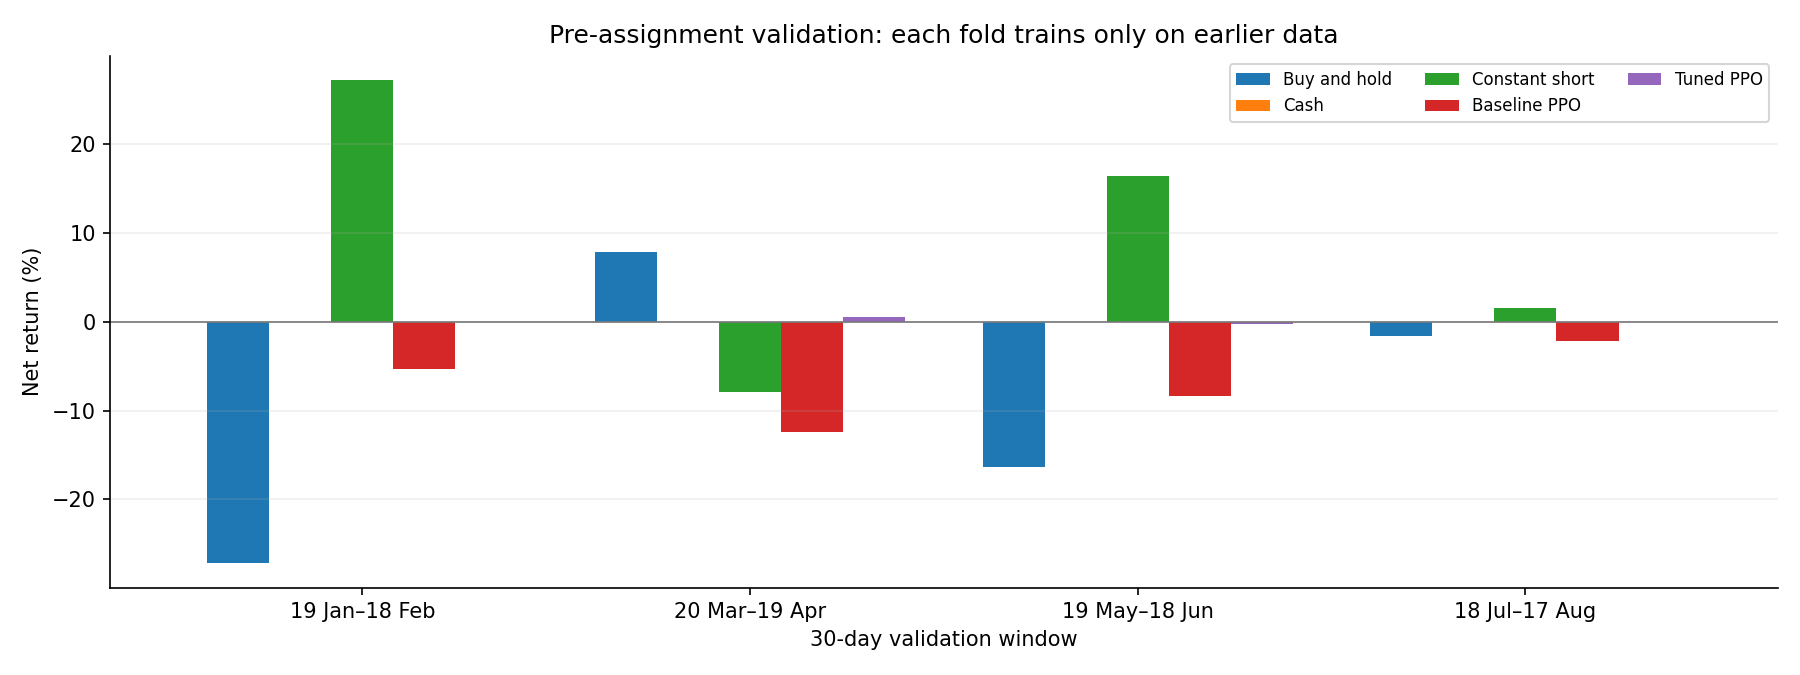

In [13]:
if (OUT / 'results_summary.md').exists():
    display(pd.read_csv(OUT / 'confirmation_individual_summary.csv').set_index('config').round(4))
    display(pd.read_csv(OUT / 'ensemble_summary.csv').set_index('config').round(4))
    selection = json.loads((OUT / 'selected_configuration.json').read_text())
    print('Frozen selection:', selection['config']['name'], '/', selection['aggregation'])
    display(pd.Series(selection['config'], name='Selected value').to_frame())
    display(Image(filename=str(OUT / 'validation_comparison.png')))
else:
    print('No new evaluation results yet; full retraining is required.')

### Training diagnostics and seed variation

Entropy measures policy concentration; value loss and explained variance describe the critic; approximate KL shows update size. These diagnostics help detect numerical or optimization problems. They do not measure out-of-sample profitability. Each trace below comes from one final training seed.

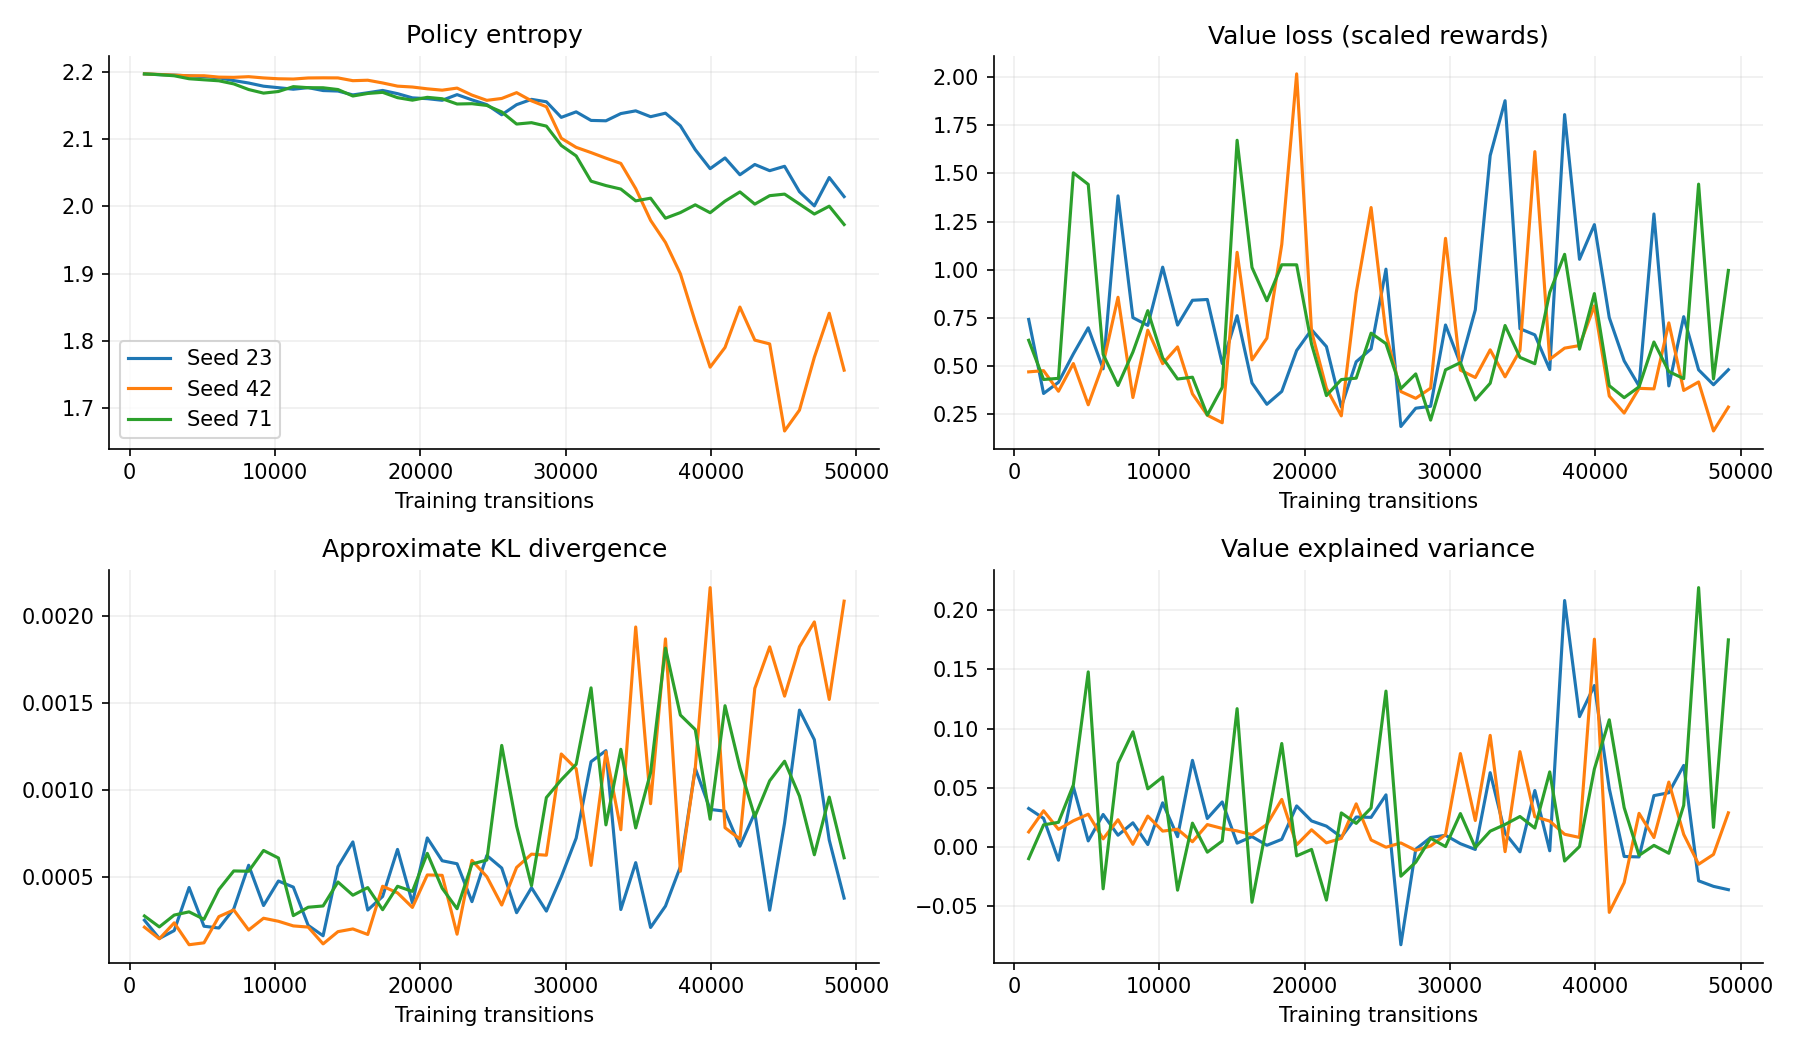

,policy,seed,portfolio_return,max_drawdown,action_changes
0,Baseline PPO,23,-0.1387,-0.1899,512
1,Baseline PPO,42,0.0387,-0.0607,403
2,Baseline PPO,71,0.1453,-0.0435,393
3,Tuned PPO,23,-0.1387,-0.1899,512
4,Tuned PPO,42,0.0387,-0.0607,403
5,Tuned PPO,71,0.1453,-0.0435,393


In [14]:
if (OUT / 'results_summary.md').exists():
    display(Image(filename=str(OUT / 'training_diagnostics.png')))
    display(pd.read_csv(OUT / 'final_seed_results.csv')[
        ['policy','seed','portfolio_return','max_drawdown','action_changes']].round(4))
else:
    print('No new evaluation results yet; full retraining is required.')

## 4. Reload and independently verify the final policy

The complete assignment window contains 744 candles and 743 decisions. The comparison includes baseline PPO, both existing DQN versions, cash, and fee-adjusted buy-and-hold. Each model uses its own saved training scaler and compatible feature set.

Reloaded policy return: -0.57%


,episode,portfolio_return,market_return,excess_return,max_drawdown,log_return,action_changes,steps,total_reward
0,1,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
1,2,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
2,3,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
3,4,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
4,5,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
5,6,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
6,7,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
7,8,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
8,9,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731
9,10,-0.005714,0.211205,-0.216919,-0.005714,-0.005731,2,743,-0.005731


,portfolio_return,max_drawdown,action_changes
policy,,,
Original DQN,-20.37%,-29.44%,17
Tuned DQN,-6.04%,-8.44%,70
Baseline PPO,14.44%,-4.02%,434
Tuned PPO,-0.57%,-0.57%,2
Cash,0.00%,0.00%,0
Buy and hold,21.11%,-7.71%,1


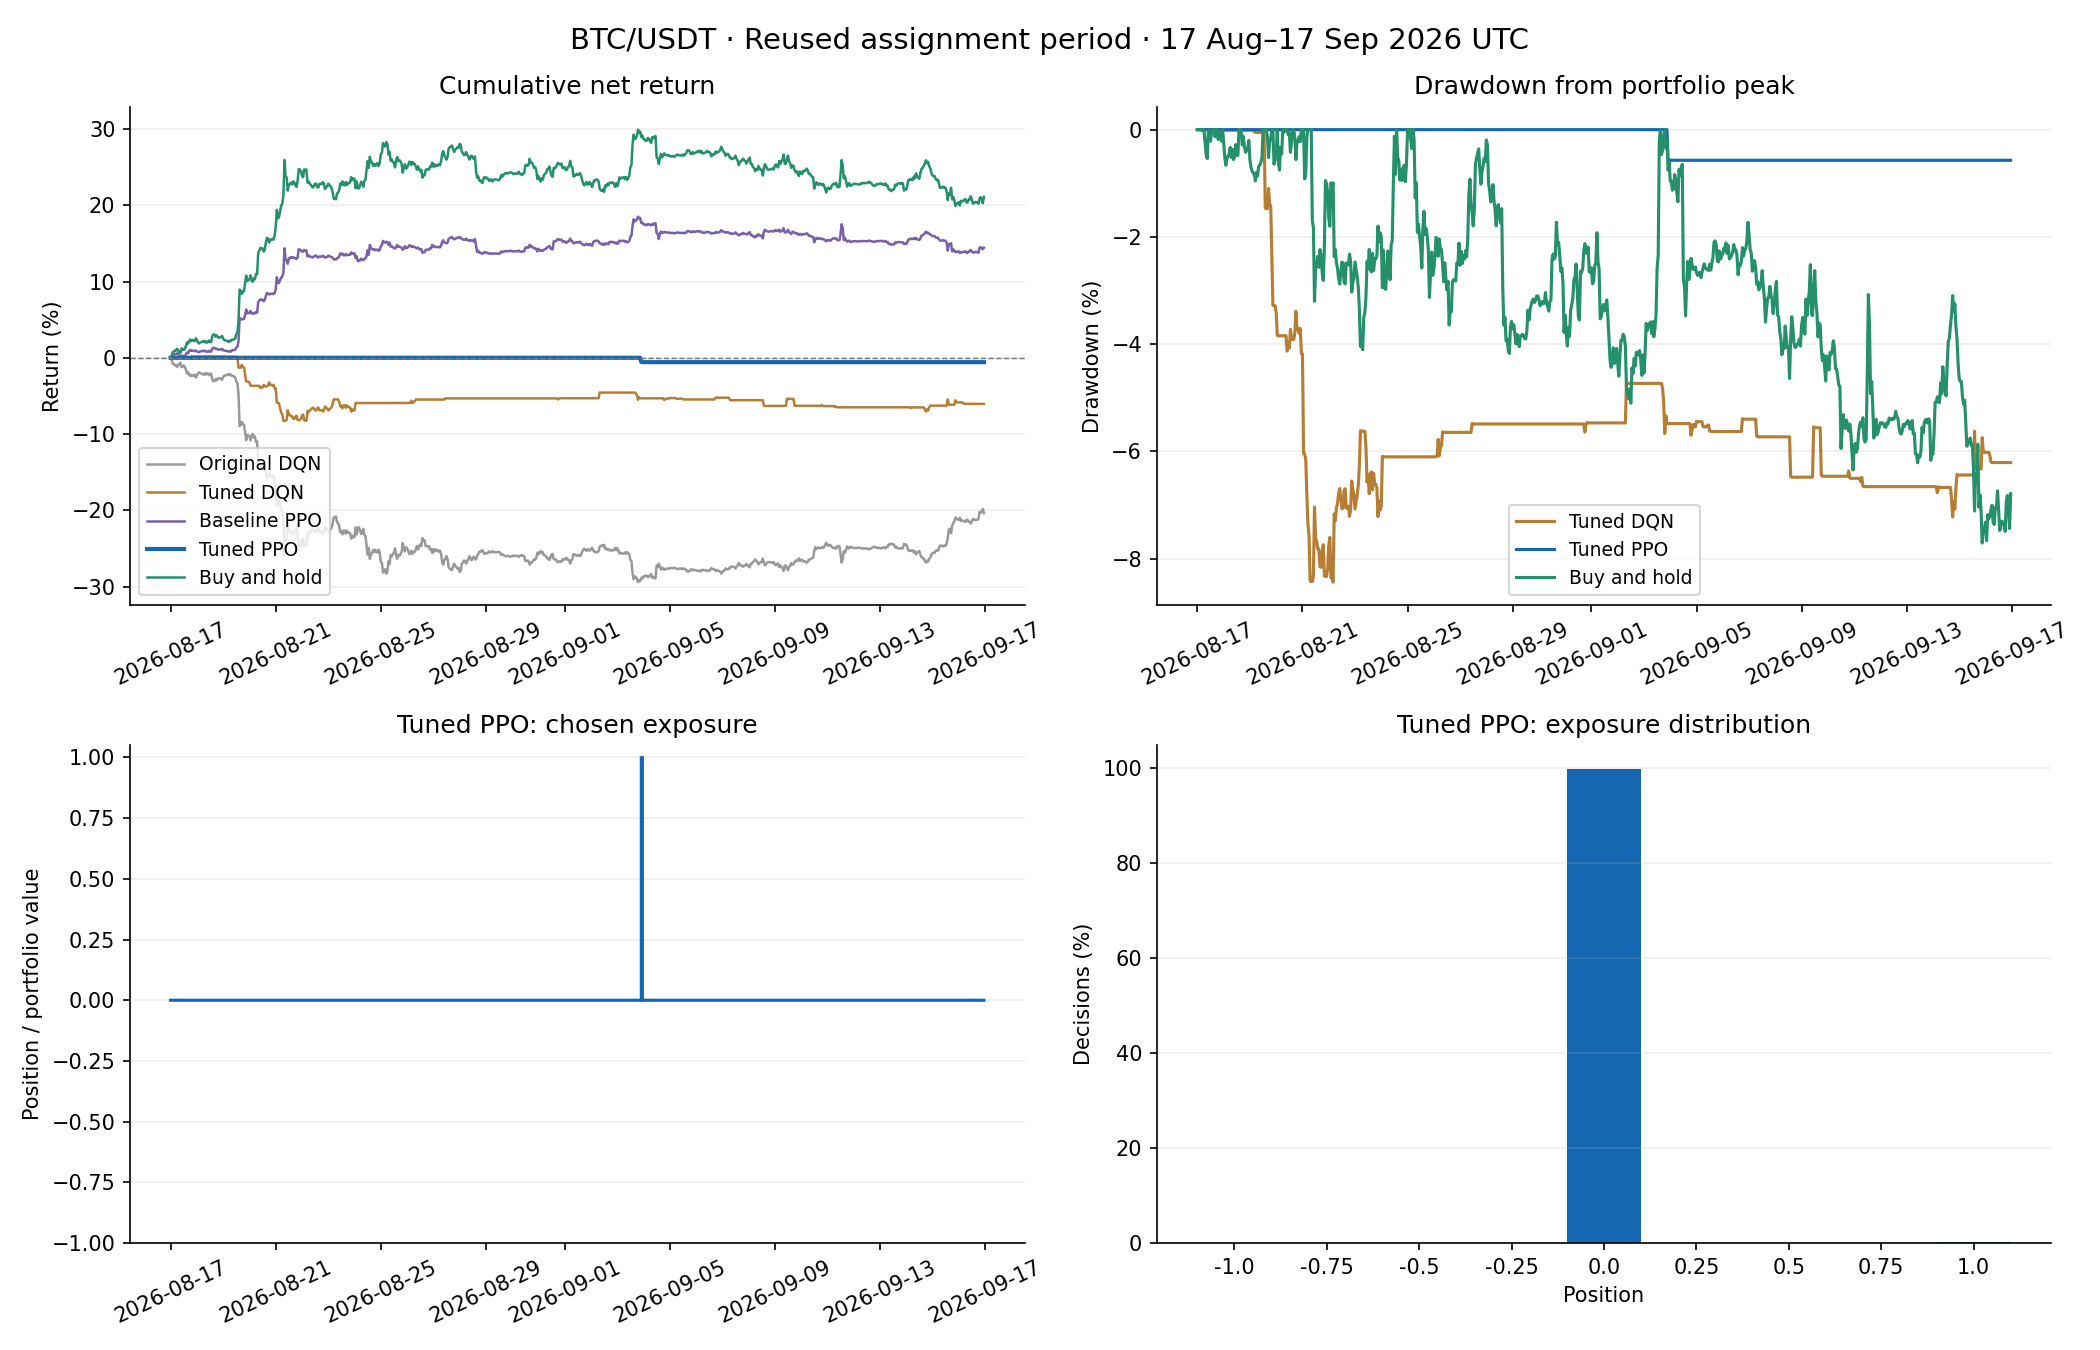

In [15]:
if (OUT / 'results_summary.md').exists():
    agent = PPOEnsemble.load(OUT / 'final_ppo_agent.pth')
    all_features = add_features(load_data(), agent.config.features)
    df_eval = all_features.loc[(all_features.index >= EVAL_START) & (all_features.index < EVAL_END)].copy()
    assert len(df_eval) == 744
    metrics, trace = rollout(agent, df_eval, return_trace=True)
    saved_results = pd.read_csv(OUT / 'evaluation_results.csv')
    assert len(saved_results) == 10 and saved_results.steps.eq(743).all()
    np.testing.assert_allclose(saved_results.portfolio_return, metrics['portfolio_return'], rtol=0, atol=1e-12)
    np.testing.assert_allclose(metrics['total_reward'], metrics['log_return'], rtol=0, atol=1e-10)
    print('Reloaded policy return:', f"{metrics['portfolio_return']:.2%}")
    display(saved_results.round(6))
    comparison = pd.read_csv(OUT / 'policy_comparison.csv').set_index('policy')
    display(comparison[['portfolio_return','max_drawdown','action_changes']].style.format(
        {'portfolio_return':'{:.2%}', 'max_drawdown':'{:.2%}', 'action_changes':'{:.0f}'}))
    display(Image(filename=str(OUT / 'policy_comparison.png')))
else:
    print('No new evaluation results yet; full retraining is required.')

Ten identical deterministic runs are reproducibility checks on one historical sequence. They are not ten independent observations. Drawdowns in raw tables are negative peak-relative returns; the written report displays their positive magnitudes. Position-change counts include the first entry from cash.

### Optional interactive environment renderer

The static plots above work on Run All. Enable the native renderer only when you want its local web interface; it starts a blocking server.

In [16]:
RUN_RENDERER = False
if RUN_RENDERER:
    from gym_trading_env.renderer import Renderer
    renderer = Renderer(render_logs_dir=str(OUT / 'render_logs'))
    renderer.run()

## 5. Measured results and interpretation

In [17]:
if (OUT / 'results_summary.md').exists():
    display(Markdown((OUT / 'results_summary.md').read_text()))
else:
    print('No new evaluation results yet; full retraining is required.')

# PPO trading project results

Selected **ppo_baseline / unanimous**, combining training seeds 23, 42, and 71.
Training history starts 2020-04-01 UTC. All PPO candidates use the nine target exposures `[-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0]`. The older DQN policies retain their original training histories and action spaces, so they are contextual benchmarks rather than controlled PPO ablations.
Tuned PPO returned **-0.57%**, a **-15.01 percentage-point** change versus baseline PPO and **+5.47 points** versus the existing tuned DQN.

| Policy | Net return | Maximum drawdown | Position changes |
|---|---:|---:|---:|
| Original DQN | -20.37% | 29.44% | 17 |
| Tuned DQN | -6.04% | 8.44% | 70 |
| Baseline PPO | 14.44% | 4.02% | 434 |
| Tuned PPO | -0.57% | 0.57% | 2 |
| Cash | 0.00% | 0.00% | 0 |
| Buy and hold | 21.11% | 7.71% | 1 |

The selected policy and baseline use the same three fitted networks. The selected policy requires unanimous action agreement; the baseline takes the highest mean action probability. Selection changed the aggregation rule, not the winning network hyperparameters. Per-seed results are therefore identical between these two labels.

The selected validation score is -0.000714; the cash benchmark scores 0.000000. Cash is a reported benchmark, not a selectable PPO configuration. A top ranking among the trained policies does not establish an advantage over cash.

## Implementation and tuning

The implementation uses a categorical actor and separate value critic, generalized advantage estimation, the clipped PPO objective, entropy regularization, gradient clipping, and a KL early-stop threshold. Rollouts are on-policy. Time limits bootstrap the final observation and break the advantage recursion at reset; bankruptcy does not bootstrap.
Initial baseline PPO averaged -10.66% per validation fold, with 213.5 position changes and 17.11% mean maximum drawdown. The strongest screening candidate, ppo_momentum, averaged 1.37%, 188.0 changes, and 5.95% drawdown. This motivated the longer confirmation stage; it does not isolate the causal contribution of each changed hyperparameter.
Seven predefined configurations were screened for 16,384 transitions across four chronological folds. The best two and the baseline were confirmed for 49,152 transitions with three seeds. Mean-probability and unanimous-vote ensembles were registered before the search. The same fixed score selects the configuration and aggregation: mean log return minus 0.25 × mean drawdown magnitude minus 0.10 × log-return standard deviation.

| Confirmed policy | Mean fold return | Worst fold return | Mean drawdown | Score |
|---|---:|---:|---:|---:|
| ppo_baseline::unanimous | 0.04% | -0.24% | 0.31% | -0.0007 |
| ppo_low_turnover::unanimous | 0.22% | -1.31% | 1.74% | -0.0036 |
| ppo_momentum::unanimous | -0.73% | -2.56% | 1.87% | -0.0134 |
| ppo_low_turnover::mean_probability | 0.68% | -9.22% | 8.54% | -0.0265 |
| ppo_momentum::mean_probability | -1.46% | -11.07% | 9.43% | -0.0497 |
| ppo_baseline::mean_probability | -7.07% | -12.43% | 12.40% | -0.1099 |

| Validation benchmark | Mean fold return | Worst fold return | Mean drawdown |
|---|---:|---:|---:|
| Constant short | 9.31% | -7.86% | 9.09% |
| Cash | 0.00% | 0.00% | 0.00% |
| Buy and hold | -9.33% | -27.20% | 17.86% |

Final parameters: `{"anneal_lr": false, "batch_size": 256, "clip_range": 0.2, "entropy_coef": 0.0, "epochs": 6, "features": "basic", "gae_lambda": 0.95, "gamma": 0.99, "hidden": 64, "lr": 0.0003, "max_grad_norm": 0.5, "n_envs": 4, "name": "ppo_baseline", "positions": [-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0], "reward_scale": 100.0, "rollout_steps": 256, "target_kl": 0.02, "turnover_penalty": 0.0, "value_coef": 0.5}`.

## Evaluation and limitations

All policies use the same cached hourly BTC/USDT candles, 0.01% trading fee, and 0.000003 hourly borrowing-interest parameter. Features are causal; scalers fit only training data. Candles are indexed by opening time; decisions use the completed candle and simulate execution at its close before the next close-to-close movement. This assumes close-price execution and omits spread, slippage, and latency.
The fixed evaluation period is 2026-08-17 (inclusive) to 2026-09-17 (exclusive), UTC: 744 candles and 743 transitions. It was previously examined in the DQN project. This is a **reused holdout comparison**, not a fresh independent test. Its results did not select this PPO configuration. Ten identical deterministic episodes verify reproducibility; they are not independent samples and do not provide a confidence interval.
Validation windows end 180, 120, 60, and 0 days before evaluation. Three of the four windows decline; cash, constant-short, and buy-and-hold validation benchmarks reveal that directional imbalance. Model seed variation is saved separately, without choosing the best final seed.
The selected policy held cash for 99.87% of evaluation decisions, with mean absolute target exposure 0.001. These participation statistics describe the observed policy; they do not establish why its performance differs from the baseline.
The expanded history contains documented gaps. Features restart after each gap and training episodes sample only continuous hourly windows. The transition budget is unchanged: 49,152 transitions per confirmed or final fit. Random episodes do not guarantee that every historical candle is visited. Validation still covers four recent 2026 windows, not all historical market regimes.
Tuned PPO did not outperform fee-adjusted buy-and-hold during the reused evaluation period. Validation-selected improvements can fail to transfer to another market regime. These experiments do not establish a persistent trading advantage.

## Files and reproduction

- `Project_PPO.ipynb`: separate, executed copy adapted to PPO, with implementation, tables, and plots.
- `ppo_trading.py`: implementation and reproducible cached search.
- `eval/ppo_202004_nine_actions/final_ppo_agent.pth`: selected ensemble with features, normalization, and aggregation.
- `eval/ppo_202004_nine_actions/evaluation_results.csv`: ten reproducibility runs; `tuned_ppo_trace.csv`: full trajectory.
- `eval/ppo_202004_nine_actions/protocol.json`: fixed candidates, folds, budgets, and source/data hashes.

```sh
.venv-rl/bin/python tests/test_ppo.py
.venv-rl/bin/python ppo_trading.py all --workers 3
.venv-rl/bin/python ppo_report.py
```

Completed matching trials are reused. To run a different protocol, preserve this experiment directory and use a new output directory. The existing DQN notebook, DQN artifacts, and course PDF are unchanged.

Algorithm reference: [Schulman et al., Proximal Policy Optimization Algorithms (2017)](https://arxiv.org/abs/1707.06347).


## 6. Presentation outline (10–15 minutes)

1. **Task and data (2 min):** hourly BTC/USDT, portfolio positions, fees, causal features, and chronological splits.
2. **PPO (3 min):** actor/critic, sampled actions, clipped probability ratios, GAE, and correct episode boundaries.
3. **Baseline and tuning (4 min):** identify the baseline's return, drawdown, and turnover; explain the candidate hypotheses and show screening versus multi-seed confirmation.
4. **Results (3 min):** compare the frozen PPO selection with baseline PPO, DQN, cash, and buy-and-hold. Show the portfolio trajectory and positions rather than training loss alone.
5. **Limits and next experiment (1–2 min):** discuss bearish validation bias, seed variability, missing execution costs, and the previously viewed evaluation month. A later untouched period or forward paper-trading study is needed to assess generalization.

Submission artifacts for this PPO version: **this notebook**, `ppo_trading.py`, `ppo_report.py`, `trading_tuning.py` (shared environment helpers), and **`eval/ppo_202004_nine_actions/evaluation_results.csv`**. Include the saved model and cache for full reproduction. The root-level DQN submission remains separate.

### Verification commands

```sh
.venv-rl/bin/python tests/test_ppo.py
.venv-rl/bin/python tests/test_tuning.py
.venv-rl/bin/python ppo_trading.py all --workers 3
```

Synthetic tests cover clipped gradients, terminal versus time-limit bootstrapping, actor and critic updates, incomplete rollouts, reproducible resets, frozen normalization, ensemble agreement, and checkpoint/backtest parity. Market performance uses only the real cached Binance history.